<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_ap_qubit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio VI, apêndice: as portas de um qubit são quaternions

## SU(2), a esfera de Bloch, a decomposição ZYZ e a aproximação de rotações com as portas H e T

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Anterior:** [X6_quaternions.ipynb](X6_quaternions.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_quaternions.ipynb))

**A ponte.** O notebook VI(a), seção 1, mostrou que os quaternions unitários são as matrizes $2\times2$ complexas unitárias de determinante 1, o grupo $SU(2)$. Em computação quântica, o estado de um **qubit** é um vetor $|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$ com $|\alpha|^2+|\beta|^2=1$, e uma **porta** de um qubit é uma matriz unitária $2\times2$. Tirando a fase global, que não tem efeito físico, toda porta de um qubit **é** um quaternion unitário, e o efeito dela sobre o estado é uma **rotação** da esfera de Bloch. Compor portas num circuito é multiplicar quaternions.

O dicionário, com as matrizes de Pauli $\sigma_x,\sigma_y,\sigma_z$:

$$q=(w,x,y,z)\ \longleftrightarrow\ U=w\,I-i\,(x\,\sigma_x+y\,\sigma_y+z\,\sigma_z),\qquad \mathbf i\leftrightarrow-i\sigma_x,\ \ \mathbf j\leftrightarrow-i\sigma_y,\ \ \mathbf k\leftrightarrow-i\sigma_z.$$

Assim, a rotação de $\theta$ em torno de $\mathbf n$, $q=(\cos\frac\theta2,\mathrm{sen}\frac\theta2\,\mathbf n)$, vira $U=e^{-i\theta\,\mathbf n\cdot\boldsymbol\sigma/2}$, a porta $R_{\mathbf n}(\theta)$ dos livros de computação quântica. O meio ângulo, que nos quaternions parecia um detalhe, é a razão de uma rotação de 360° multiplicar o estado de um elétron por $-1$.

**Roteiro**
1. O dicionário, conferido
2. As portas de sempre como rotações
3. A esfera de Bloch: a porta gira o vetor de Bloch
4. A decomposição ZYZ de uma porta qualquer
5. Aproximar uma rotação qualquer só com as portas H e T

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

def qmul(a, b):
    """Produto de Hamilton de quaternions guardados como arrays (w, x, y, z); aceita pilhas (..., 4)."""
    a, b = np.asarray(a), np.asarray(b)
    w1, x1, y1, z1 = np.moveaxis(a, -1, 0); w2, x2, y2, z2 = np.moveaxis(b, -1, 0)
    return np.stack([w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2,
                     w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2,
                     w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2,
                     w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2], axis=-1)

def qconj(q):
    q = np.asarray(q); return q * np.array([1, -1, -1, -1])

def qnorm(q):
    q = np.asarray(q, float); return q / np.linalg.norm(q, axis=-1, keepdims=True)

def qrot(q, v):
    """O vetor v (3,) levado pela rotação q: a parte vetorial de q (0, v) q*."""
    return qmul(qmul(q, np.concatenate([[0.0], v])), qconj(q))[1:]

def qmat(q):
    """A matriz de rotação R(q), com R v = q v q* (q unitário)."""
    w, x, y, z = q
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)],
                     [2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)],
                     [2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)]])

def mat_q(R):
    """De uma matriz de rotação para um quaternion (método de Shepperd: usa o maior pivô, sem perder dígitos)."""
    t = np.trace(R); d = np.diag(R)
    k = np.argmax([t, *d])
    if k == 0:
        w = np.sqrt(1 + t) / 2; q = [w, (R[2, 1] - R[1, 2]) / (4 * w), (R[0, 2] - R[2, 0]) / (4 * w), (R[1, 0] - R[0, 1]) / (4 * w)]
    elif k == 1:
        x = np.sqrt(1 + 2 * d[0] - t) / 2; q = [(R[2, 1] - R[1, 2]) / (4 * x), x, (R[0, 1] + R[1, 0]) / (4 * x), (R[0, 2] + R[2, 0]) / (4 * x)]
    elif k == 2:
        y = np.sqrt(1 + 2 * d[1] - t) / 2; q = [(R[0, 2] - R[2, 0]) / (4 * y), (R[0, 1] + R[1, 0]) / (4 * y), y, (R[1, 2] + R[2, 1]) / (4 * y)]
    else:
        z = np.sqrt(1 + 2 * d[2] - t) / 2; q = [(R[1, 0] - R[0, 1]) / (4 * z), (R[0, 2] + R[2, 0]) / (4 * z), (R[1, 2] + R[2, 1]) / (4 * z), z]
    q = np.array(q); return q if q[0] >= 0 else -q

def qexp(phi):
    """Exp do vetor de rotação φ = θ n: (cos(θ/2), sen(θ/2) n), com o sinc estável perto de θ = 0."""
    phi = np.asarray(phi, float); th = np.linalg.norm(phi)
    return np.concatenate([[np.cos(th / 2)], 0.5 * sinc(th / 2) * phi])

def qlog(q):
    """Log: o vetor de rotação φ de q (escolhendo o representante com w ≥ 0, isto é, |θ| ≤ π)."""
    q = np.asarray(q, float)
    if q[0] < 0: q = -q
    s = np.linalg.norm(q[1:]); th = 2 * np.arctan2(s, q[0])     # atan2: estável para ângulos pequenos e grandes
    return 2 * q[1:] / sinc(th / 2)

def slerp(q0, q1, s):
    """Interpolação esférica: q0 Exp(s Log(q0* q1)), pelo arco mais curto."""
    return qmul(q0, qexp(s * qlog(qmul(qconj(q0), q1))))

def chapeu(v):
    """A matriz antissimétrica [v]×, com [v]× u = v × u."""
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

rng = np.random.default_rng(65)
I2 = np.eye(2, dtype=complex)
SX = np.array([[0, 1], [1, 0]], dtype=complex); SY = np.array([[0, -1j], [1j, 0]]); SZ = np.array([[1, 0], [0, -1]], dtype=complex)

def U_de_q(q):
    w, x, y, z = q; return w * I2 - 1j * (x * SX + y * SY + z * SZ)

def q_de_U(U):
    """O quaternion de uma porta (tirando a fase global: U/√det U está em SU(2)); sinal com w ≥ 0."""
    V = U / np.sqrt(complex(np.linalg.det(U)))
    q = np.array([np.trace(V).real / 2, -np.trace(SX @ V).imag / 2, -np.trace(SY @ V).imag / 2, -np.trace(SZ @ V).imag / 2])
    return q if q[0] >= 0 else -q

def mesma_rotacao(a, b): return min(np.linalg.norm(a - b), np.linalg.norm(a + b))

## 1. O dicionário, conferido

In [2]:
confere("−iσx, −iσy, −iσz satisfazem i² = j² = k² = ijk = −1",
        [(-1j * SX) @ (-1j * SX), (-1j * SY) @ (-1j * SY), (-1j * SZ) @ (-1j * SZ), (-1j * SX) @ (-1j * SY) @ (-1j * SZ)], [-I2] * 4, tol=1e-15)
a, b = qnorm(rng.normal(size=4)), qnorm(rng.normal(size=4))
confere("U(ab) = U(a) U(b): compor portas é multiplicar quaternions", U_de_q(qmul(a, b)), U_de_q(a) @ U_de_q(b), tol=1e-14)
confere("U(q) é unitária com determinante 1", [U_de_q(a) @ U_de_q(a).conj().T, np.linalg.det(U_de_q(a)) * I2], [I2, I2], tol=1e-14)
confere("e o caminho de volta recupera q (a menos do sinal)", mesma_rotacao(q_de_U(U_de_q(a)), a), 0, tol=1e-14)
fase = np.exp(1j * 0.7)
confere("uma fase global não muda o quaternion", mesma_rotacao(q_de_U(fase * U_de_q(a)), a), 0, tol=1e-14)

OK   −iσx, −iσy, −iσz satisfazem i² = j² = k² = ijk = −1:  diferença máxima = 0.00e+00
OK   U(ab) = U(a) U(b): compor portas é multiplicar quaternions:  diferença máxima = 5.55e-17
OK   U(q) é unitária com determinante 1:  diferença máxima = 2.22e-16
OK   e o caminho de volta recupera q (a menos do sinal):  diferença máxima = 1.93e-16
OK   uma fase global não muda o quaternion:  diferença máxima = 5.55e-17


## 2. As portas de sempre como rotações

In [3]:
portas = {"X": SX, "Y": SY, "Z": SZ, "H (Hadamard)": np.array([[1, 1], [1, -1]]) / np.sqrt(2),
          "S": np.diag([1, 1j]), "T": np.diag([1, np.exp(1j * np.pi / 4)])}
print(f"{'porta':14s} ângulo     eixo")
for nome, U in portas.items():
    q = q_de_U(U); phi = qlog(q); th = np.linalg.norm(phi)
    print(f"{nome:14s} {np.degrees(th):6.1f}°    {np.round(phi / th, 4)}")
q = lambda nome: q_de_U(portas[nome])
confere("H é meia volta em torno de (x + z)/√2", mesma_rotacao(q("H (Hadamard)"), np.array([0, 1, 0, 1]) / np.sqrt(2)), 0, tol=1e-15)
confere("T² = S e S² = Z (como rotações)", [mesma_rotacao(qmul(q("T"), q("T")), q("S")), mesma_rotacao(qmul(q("S"), q("S")), q("Z"))], [0, 0], tol=1e-15)
confere("H Z H = X: o Hadamard troca os eixos x e z", mesma_rotacao(qmul(qmul(q("H (Hadamard)"), q("Z")), q("H (Hadamard)")), q("X")), 0, tol=1e-15)

porta          ângulo     eixo
X               180.0°    [ 1. -0. -0.]
Y               180.0°    [-0.  1. -0.]
Z               180.0°    [-0. -0.  1.]
H (Hadamard)    180.0°    [ 0.7071 -0.      0.7071]
S                90.0°    [-0. -0.  1.]
T                45.0°    [-0. -0.  1.]
OK   H é meia volta em torno de (x + z)/√2:  diferença máxima = 1.57e-16
OK   T² = S e S² = Z (como rotações):  diferença máxima = 2.22e-16
OK   H Z H = X: o Hadamard troca os eixos x e z:  diferença máxima = 2.22e-16


## 3. A esfera de Bloch

O estado $|\psi\rangle$ tem um **vetor de Bloch** $\mathbf r=(\langle\sigma_x\rangle,\langle\sigma_y\rangle,\langle\sigma_z\rangle)$, com $\langle\sigma\rangle=\langle\psi|\sigma|\psi\rangle$, que é um ponto da esfera unitária. $|0\rangle$ é o polo norte, $|1\rangle$ o polo sul. A probabilidade de medir 0 é $(1+r_z)/2$. A porta $U(q)$ leva $\mathbf r$ em $R(q)\,\mathbf r$: é exatamente a rotação do notebook VI(a).

In [4]:
def bloch(psi):
    return np.array([(psi.conj() @ s @ psi).real for s in (SX, SY, SZ)])

psi = rng.normal(size=2) + 1j * rng.normal(size=2); psi = psi / np.linalg.norm(psi)
for _ in range(3):
    q_ = qnorm(rng.normal(size=4))
    confere("o vetor de Bloch de U|ψ⟩ é R(q) aplicado ao de |ψ⟩", bloch(U_de_q(q_) @ psi), qmat(q_) @ bloch(psi), tol=1e-14)
confere("P(0) = (1 + r_z)/2", abs(psi[0])**2, (1 + bloch(psi)[2]) / 2, tol=1e-15)
psi2 = U_de_q(qexp(2 * np.pi * np.array([0, 0, 1.0]))) @ psi
confere("uma rotação de 360° devolve o vetor de Bloch", bloch(psi2), bloch(psi), tol=1e-14)
confere("mas multiplica o estado por −1", psi2, -psi, tol=1e-14)

OK   o vetor de Bloch de U|ψ⟩ é R(q) aplicado ao de |ψ⟩:  diferença máxima = 5.55e-17
OK   o vetor de Bloch de U|ψ⟩ é R(q) aplicado ao de |ψ⟩:  diferença máxima = 2.22e-16
OK   o vetor de Bloch de U|ψ⟩ é R(q) aplicado ao de |ψ⟩:  diferença máxima = 1.11e-16
OK   P(0) = (1 + r_z)/2:  diferença máxima = 2.22e-16
OK   uma rotação de 360° devolve o vetor de Bloch:  diferença máxima = 1.67e-16
OK   mas multiplica o estado por −1:  diferença máxima = 9.71e-17


## 4. A decomposição ZYZ

Toda porta de um qubit pode ser escrita como $U=e^{i\alpha}R_z(\beta)\,R_y(\gamma)\,R_z(\delta)$. São os **ângulos de Euler** ZYZ da rotação, e saem do quaternion com $\mathrm{atan2}$, sem passar pela matriz $2\times2$. Para $q=(w,x,y,z)$:

$$\gamma=2\,\mathrm{atan2}\big(\sqrt{x^2+y^2},\sqrt{w^2+z^2}\big),\qquad \beta+\delta=2\,\mathrm{atan2}(z,w),\qquad \beta-\delta=2\,\mathrm{atan2}(-x,y).$$

Como no notebook VI(a), seção 4, esses ângulos têm singularidades (em $\gamma=0$ e $\gamma=\pi$, só a soma ou só a diferença de $\beta$ e $\delta$ fica definida). Para um compilador de circuitos, isso não é problema: qualquer escolha serve.

In [5]:
Rz = lambda a_: qexp([0, 0, a_]); Ry = lambda a_: qexp([0, a_, 0])

def zyz(q):
    w, x, y, z = q
    gama = 2 * np.arctan2(np.hypot(x, y), np.hypot(w, z))
    soma, dif = 2 * np.arctan2(z, w), 2 * np.arctan2(-x, y)
    return (soma + dif) / 2, gama, (soma - dif) / 2

pior = 0
for _ in range(1000):
    U = np.exp(1j * rng.uniform(0, 2 * np.pi)) * U_de_q(qnorm(rng.normal(size=4)))      # uma porta qualquer, com fase
    be, ga, de = zyz(q_de_U(U))
    pior = max(pior, mesma_rotacao(qmul(qmul(Rz(be), Ry(ga)), Rz(de)), q_de_U(U)))
confere("ZYZ reconstrói 1000 portas aleatórias", pior, 0, tol=1e-13)

OK   ZYZ reconstrói 1000 portas aleatórias:  diferença máxima = 5.88e-16


## 5. Aproximar uma rotação qualquer só com H e T

Um computador quântico tolerante a falhas não executa rotações arbitrárias: ele tem um conjunto finito de portas "baratas" de proteger contra erros, tipicamente H e T. Toda outra porta tem de ser **aproximada** por uma sequência dessas. As portas H e T geram um subgrupo **denso** de $SU(2)$: com sequências cada vez mais longas, chega-se tão perto quanto se queira de qualquer rotação.

Aqui, a força bruta com quaternions: enumerar todas as palavras em H e T até um comprimento $L$, guardando só os elementos novos (o quaternion, a menos do sinal, é a chave), e medir a distância da melhor palavra a 20 rotações-alvo sorteadas. Com $N$ elementos espalhados em $SO(3)$, que tem dimensão 3, o espaçamento típico deve cair como $N^{-1/3}$.

palavras de até  5 portas:      32 rotações distintas;  erro médio da melhor aproximação  49.78°
palavras de até 10 portas:     266 rotações distintas;  erro médio da melhor aproximação  19.29°
palavras de até 15 portas:    1158 rotações distintas;  erro médio da melhor aproximação  11.80°
palavras de até 20 portas:    4428 rotações distintas;  erro médio da melhor aproximação   9.32°
palavras de até 25 portas:   16408 rotações distintas;  erro médio da melhor aproximação   5.17°
palavras de até 30 portas:   60622 rotações distintas;  erro médio da melhor aproximação   3.50°
palavras de até 34 portas:  172441 rotações distintas;  erro médio da melhor aproximação   2.78°
inclinação de log(erro) contra log(N), para L ≥ 15: -0.314  (a cobertura de um espaço de dimensão 3 dá −1/3)
OK   o erro cai com N aproximadamente como N^(−1/3):  diferença máxima = 1.98e-02
o número de rotações distintas cresce uns 30% a cada porta a mais


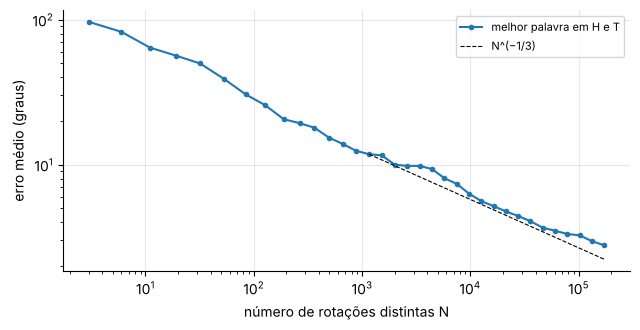

In [6]:
Hq, Tq = q("H (Hadamard)"), q("T")
alvos = qnorm(rng.normal(size=(20, 4)))
def chave(q_):
    i_ = np.argmax(np.abs(q_) > 1e-9); q_ = q_ if q_[i_] > 0 else -q_
    return tuple(np.round(q_, 9))

vistos, todos, fronteira, tabela = {chave(np.array([1.0, 0, 0, 0]))}, [np.array([1.0, 0, 0, 0])], [np.array([1.0, 0, 0, 0])], []
for L in range(1, 35):
    nova = []
    for q_ in fronteira:
        for g_ in (Hq, Tq):
            p_ = qmul(q_, g_); k_ = chave(p_)
            if k_ not in vistos: vistos.add(k_); nova.append(p_)
    fronteira = nova; todos += nova
    cmax = np.abs(np.array(todos) @ alvos.T).max(axis=0)
    tabela.append((L, len(todos), np.degrees(np.mean(2 * np.arccos(np.clip(cmax, -1, 1))))))
tabela = np.array(tabela)
for L, N, e_ in tabela[[4, 9, 14, 19, 24, 29, 33]]:
    print(f"palavras de até {int(L):2d} portas: {int(N):7d} rotações distintas;  erro médio da melhor aproximação {e_:6.2f}°")
m_ = tabela[:, 0] >= 15
incl = np.polyfit(np.log(tabela[m_, 1]), np.log(tabela[m_, 2]), 1)[0]
print(f"inclinação de log(erro) contra log(N), para L ≥ 15: {incl:.3f}  (a cobertura de um espaço de dimensão 3 dá −1/3)")
confere("o erro cai com N aproximadamente como N^(−1/3)", incl, -1 / 3, tol=0.08)
crescimento = np.exp(np.polyfit(tabela[m_, 0], np.log(tabela[m_, 1]), 1)[0])
print(f"o número de rotações distintas cresce uns {100 * (crescimento - 1):.0f}% a cada porta a mais")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.loglog(tabela[:, 1], tabela[:, 2], "o-", ms=3, label="melhor palavra em H e T")
ax.loglog(tabela[m_, 1], tabela[m_, 2][0] * (tabela[m_, 1] / tabela[m_, 1][0])**(-1 / 3), "k--", lw=0.8, label="N^(−1/3)")
ax.set_xlabel("número de rotações distintas N"); ax.set_ylabel("erro médio (graus)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.** O dicionário funciona nos dois sentidos: compor portas é multiplicar quaternions, e a porta gira o vetor de Bloch pela matriz $R(q)$ do notebook VI(a). As portas conhecidas são rotações simples (o Hadamard é meia volta em torno da bissetriz de $x$ e $z$; T é um oitavo de volta em torno de $z$). Uma rotação de 360° devolve o vetor de Bloch, mas troca o sinal do estado: é a dupla cobertura, agora com consequência física (uma fase relativa, se esse qubit estiver emaranhado com outro). A decomposição ZYZ reconstrói mil portas aleatórias até o arredondamento.

Na aproximação com H e T, o número de rotações distintas cresce cerca de 30% a cada porta a mais, e o erro médio cai devagar, como $N^{-1/3}$: com palavras de até 34 portas e 170 mil candidatas, o erro ainda é de uns 2,8°. A busca exaustiva fica cara rapidamente. É por isso que existem algoritmos que constroem a sequência sem enumerar tudo: o de Solovay–Kitaev, recursivo e geral, e, para rotações em torno de $z$, os métodos de teoria dos números de Ross e Selinger, que usam exatamente a aritmética de quaternions com coeficientes em $\mathbb Z[\tfrac1{\sqrt2}]$.

## Exercícios

1. **Portas de dois qubits?** Uma porta de dois qubits é uma matriz $4\times4$ unitária, e o grupo $SU(4)$ tem dimensão 15. Quaternions não bastam. Mas $SU(2)\times SU(2)$ (uma porta em cada qubit, sem interação) é feito de pares de quaternions. Escreva o produto de Kronecker $U(a)\otimes U(b)$ e confira que compor duas dessas portas é multiplicar os pares.
2. **Erros de calibração.** Se a porta T do aparelho gira $\pi/4+\epsilon$ em vez de $\pi/4$, como o erro se acumula numa palavra de 30 portas? Compare com o erro de uma rotação que se repete 30 vezes (notebook VI(c), integradores).
3. **A distância certa.** Mostre que a distância usada aqui, $2\arccos\lvert\langle q_1,q_2\rangle\rvert$, é o ângulo da rotação $q_1^*q_2$, e que ela não depende do sinal de $q_1$ e $q_2$ (nem da fase global das portas).